Linear Regression (log) MAE: 107,940.92 €
Random Forest (log) MAE: 87,267.31 €


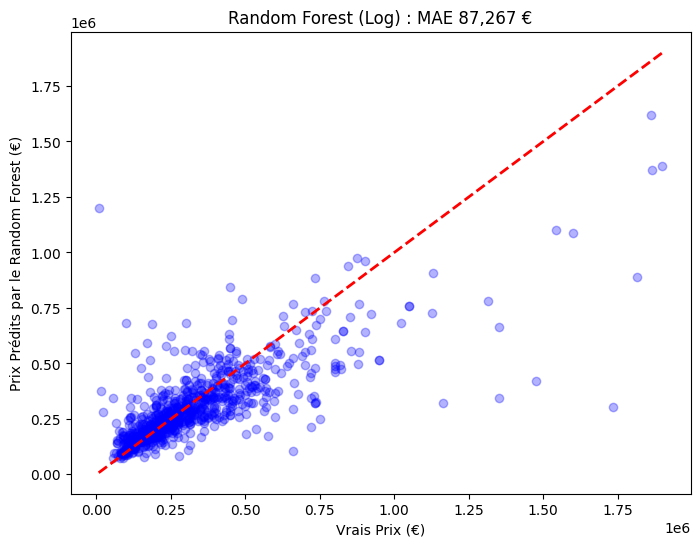


--- Importance des variables dans le modèle ---
- surface_reelle_bati: 50.6%
- latitude: 22.2%
- longitude: 20.3%
- is_maison: 3.5%
- nombre_pieces_principales: 3.4%


In [38]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

# 1. Charger les données en ignorant les lignes mal formées du CSV
df = pd.read_csv("33.csv", low_memory=False, on_bad_lines="skip")

# 2. Nettoyage
df_clean = df[
    (df["nature_mutation"] == "Vente")
    & (df["type_local"].isin(["Maison", "Appartement"]))
].copy()
df_clean = df_clean.dropna(
    subset=[
        "valeur_fonciere",
        "surface_reelle_bati",
        "nombre_pieces_principales",
        "latitude",
        "longitude"
    ]
)
df_clean = df_clean[
    (df_clean["valeur_fonciere"] > 1000)
    & (df_clean["valeur_fonciere"] < 2_000_000)
]
df_clean["is_maison"] = (df_clean["type_local"] == "Maison").astype(int)

features = [
    "surface_reelle_bati",
    "nombre_pieces_principales",
    "is_maison",
     "latitude",
     "longitude"
]
X = df_clean[features]
y = df_clean["valeur_fonciere"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Modèles & Résultats

lr_log = LinearRegression()


lr_log.fit(X_train, np.log1p(y_train))


y_pred_lr_log = np.expm1(lr_log.predict(X_test))


mae_lr_log = mean_absolute_error(y_test, y_pred_lr_log)
print(f"Linear Regression (log) MAE: {mae_lr_log:,.2f} €")

# 1. On entraîne avec le log
rf = RandomForestRegressor(n_estimators=1000, random_state=42, n_jobs=-1)
rf.fit(X_train, np.log1p(y_train))


y_pred_log_rf = rf.predict(X_test)

# 3. ON CONVERTIT EN VRAIS EUROS
y_pred_rf = np.expm1(y_pred_log_rf)

# 4. Maintenant le MAE et le graphique vont fonctionner parfaitement
mae_rf_log = mean_absolute_error(y_test, y_pred_rf)
print(f"Random Forest (log) MAE: {mae_rf_log:,.2f} €")

# 5. Graphique
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color="blue")
plt.xlabel("Vrais Prix (€)")
plt.ylabel("Prix Prédits par le Random Forest (€)")
plt.title(f"Random Forest (Log) : MAE {mae_rf_log:,.0f} €")
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2
)
plt.show()


# B. Importance des variables dans le modèle
importances = rf.feature_importances_
print("\n--- Importance des variables dans le modèle ---")
for feature, imp in sorted(
    zip(features, importances), key=lambda x: x[1], reverse=True
):
    print(f"- {feature}: {imp*100:.1f}%")

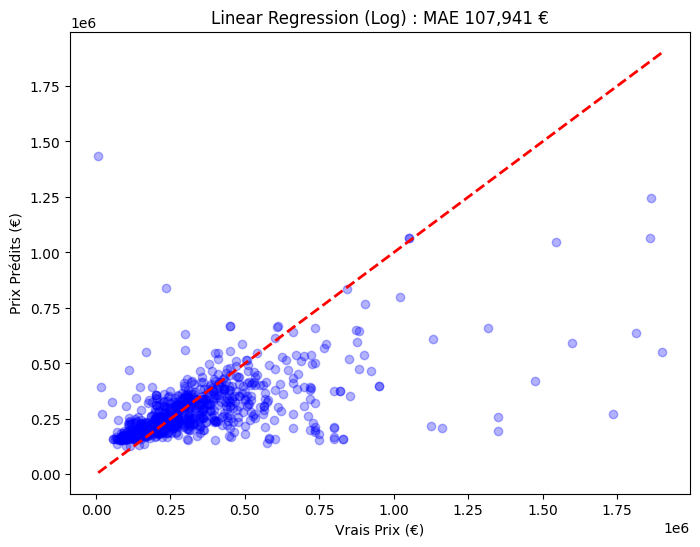

In [39]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr_log, alpha=0.3, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Vrais Prix (€)")
plt.ylabel("Prix Prédits (€)")
plt.title(f"Linear Regression (Log) : MAE {mae_lr_log:,.0f} €")
plt.show()

XGBoost MAE: 85,500.32 €


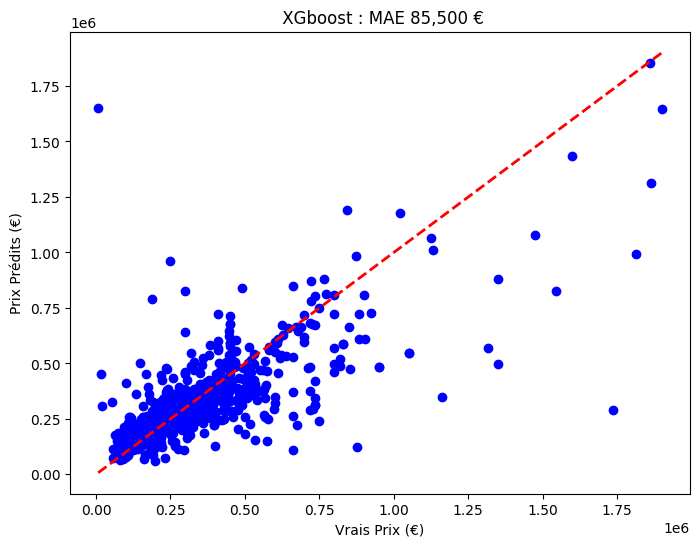

In [33]:



# 1. Initialisation du modèle XGBoost
xgb= XGBRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,  # On fixe une profondeur idéale pour les arbres
    random_state=42,
    n_jobs=-1,
)
# 2. Entraînement avec le log des prix (comme pour le Random Forest)
xgb.fit(X_train, np.log1p(y_train))

# 3. Prédiction et conversion en euros réels avec np.expm1
y_pred_log_xgb = xgb.predict(X_test)
y_pred_xgb = np.expm1(y_pred_log_xgb)

# 4. Affichage du nouveau score d'erreur
print(f"XGBoost MAE: {mean_absolute_error(y_test, y_pred_xgb):,.2f} €")

mae_xgb=mean_absolute_error(y_test, y_pred_xgb)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_xgb, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Vrais Prix (€)")
plt.ylabel("Prix Prédits (€)")
plt.title(f" XGboost : MAE {mae_xgb:,.0f} €")
plt.show()